# Chapter 2. Background Research
## 2.4.3 Noise-Level Based Parameter Mappings

The values in this notebook are invented for illustration only. They are not experimental results.

In [1]:
from pathlib import Path
from matplotlib import pyplot as plt
import numpy as np

# Find the project directory
if Path.cwd().name == "notebooks":
    project_dir = Path.cwd().parent
else:
    project_dir = Path.cwd()

# Save figures in a folder with the notebook name
plot_dir = project_dir / "results" / "Chapter2_ParameterMappings"
plot_dir.mkdir(parents=True, exist_ok=True)

## 2.4.3.1 Lookup table

A lookup table stores selected noise levels and their parameters. It gives a simple discrete mapping.


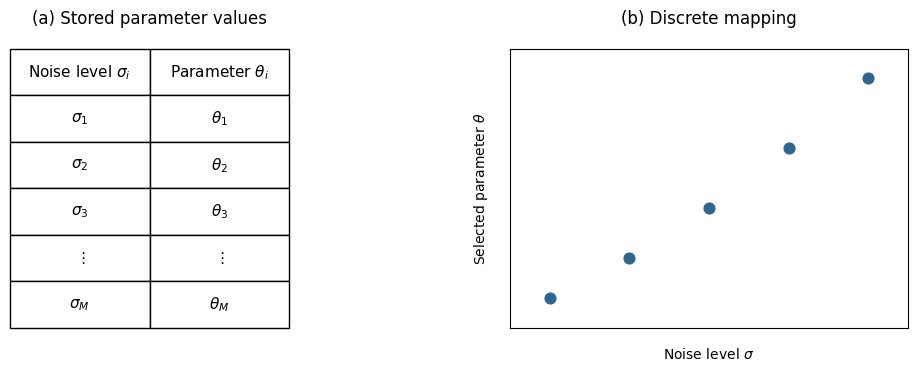

In [2]:
# Positions used only to draw the conceptual points
point_x = np.arange(5)
point_y = np.array([0.6, 1.0, 1.5, 2.1, 2.8])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].set_box_aspect(1)
axes[1].set_box_aspect(0.7)

# Show symbolic calibration pairs
table_values = [
    [r"$\sigma_1$", r"$\theta_1$"],
    [r"$\sigma_2$", r"$\theta_2$"],
    [r"$\sigma_3$", r"$\theta_3$"],
    [r"$\vdots$", r"$\vdots$"],
    [r"$\sigma_M$", r"$\theta_M$"]
]

table = axes[0].table(
    cellText=table_values,
    colLabels=[r"Noise level $\sigma_i$", r"Parameter $\theta_i$"],
    cellLoc="center", colLoc="center",
    bbox=[0, 0, 1, 1]
)

table.auto_set_font_size(False)
table.set_fontsize(11)

axes[0].axis("off")
axes[0].set_title("(a) Stored parameter values", pad=18)

# Show the conceptual discrete mapping
axes[1].scatter(point_x, point_y, color="#2F6690", s=60)
axes[1].set_title("(b) Discrete mapping", pad=18)
axes[1].set_xlabel(r"Noise level $\sigma$", labelpad=14)
axes[1].set_ylabel(r"Selected parameter $\theta$", labelpad=14)
axes[1].set_xlim(-0.5, 4.5)
axes[1].set_ylim(0.3, 3.1)
axes[1].set_xticks([])
axes[1].set_yticks([])

fig.subplots_adjust(
    left=0.07, right=0.97, bottom=0.18,
    top=0.80, wspace=0.3
)

fig.savefig(
    plot_dir / "lookup_table_mapping.png",
    dpi=300, bbox_inches="tight"
)

plt.show()


## 2.4.3.2 Linear interpolation

Linear interpolation estimates values between neighbouring calibration points. It gives a continuous mapping.


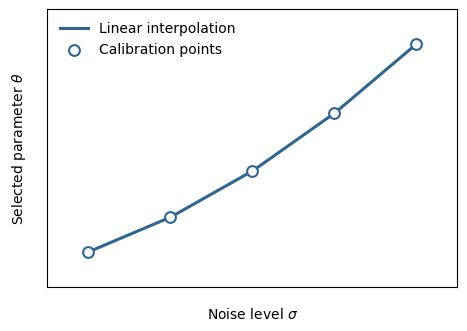

In [3]:
# Example calibration data for illustration only
noise_levels = np.array([0.04, 0.08, 0.12, 0.16, 0.20])
parameters = np.array([0.05, 0.08, 0.12, 0.17, 0.23])

# Calculate values between the calibration points
noise_range = np.linspace(noise_levels.min(), noise_levels.max(), 300)
interpolated_values = np.interp(noise_range, noise_levels, parameters)

# Create the interpolation figure
fig, axis = plt.subplots(figsize=(5, 4.2))

axis.plot(
    noise_range, interpolated_values,
    color="#2F6690", linewidth=2.2,
    label="Linear interpolation"
)

axis.scatter(
    noise_levels, parameters,
    facecolors="white", edgecolors="#2F6690",
    linewidth=1.5, s=60, zorder=3,
    label="Calibration points"
)

# axis.set_title("Linear Interpolation Mapping", pad=18)

axis.set_xlabel(r"Noise level $\sigma$", labelpad=14)
axis.set_ylabel(r"Selected parameter $\theta$", labelpad=14)
axis.set_xlim(0.02, 0.22)
axis.set_ylim(0.02, 0.26)
axis.set_xticks([])
axis.set_yticks([])
axis.legend(frameon=False, loc="upper left")

fig.subplots_adjust(
    left=0.14, right=0.96,
    bottom=0.18, top=0.84
)

fig.savefig(
    plot_dir / "linear_interpolation_mapping.png",
    dpi=300, bbox_inches="tight"
)

plt.show()


## 2.4.3.3 Fitted functions

A fitted function represents the mapping with a simple curve. Linear and quadratic examples are shown below.


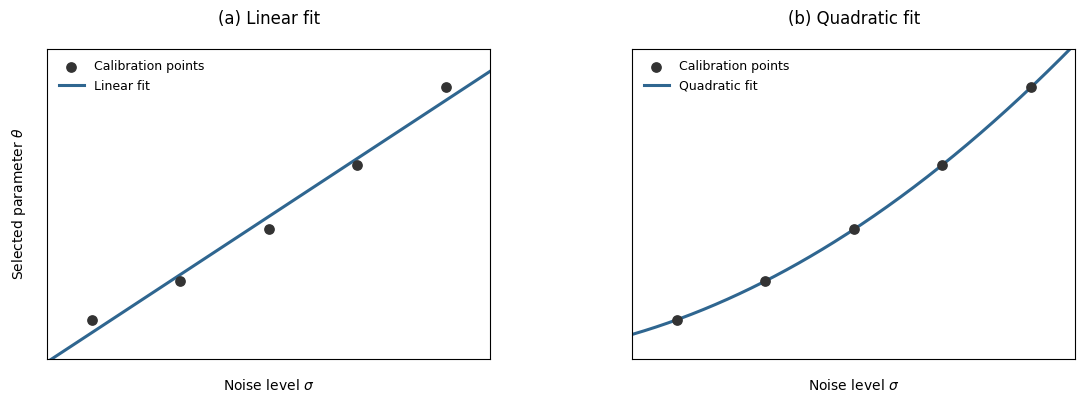

In [4]:
# Example calibration data for illustration only
noise_levels = np.array([0.04, 0.08, 0.12, 0.16, 0.20])
parameters = np.array([0.05, 0.08, 0.12, 0.17, 0.23])

# Control the figure layout
figure_width = 13
figure_height = 5
panel_aspect = 0.70
panel_spacing = 0.0

# Fit linear and quadratic functions
noise_range = np.linspace(0.02, 0.22, 300)
linear_coefficients = np.polyfit(noise_levels, parameters, 1)
quadratic_coefficients = np.polyfit(noise_levels, parameters, 2)

linear_values = np.polyval(linear_coefficients, noise_range)
quadratic_values = np.polyval(quadratic_coefficients, noise_range)

# Create the comparison figure
fig, axes = plt.subplots(
    1, 2, figsize=(figure_width, figure_height),
    sharex=True, sharey=True,
    gridspec_kw={"width_ratios": [1, 1]}
)

# Show the linear fitted function
axes[0].scatter(
    noise_levels, parameters,
    color="#333333", s=45,
    label="Calibration points", zorder=3
)
axes[0].plot(
    noise_range, linear_values,
    color="#2F6690", linewidth=2.2,
    label="Linear fit"
)
axes[0].set_title("(a) Linear fit", pad=18)
axes[0].legend(frameon=False, fontsize=9)

# Show the quadratic fitted function
axes[1].scatter(
    noise_levels, parameters,
    color="#333333", s=45,
    label="Calibration points", zorder=3
)
axes[1].plot(
    noise_range, quadratic_values,
    color="#2F6690", linewidth=2.2,
    label="Quadratic fit"
)
axes[1].set_title("(b) Quadratic fit", pad=18)
axes[1].legend(frameon=False, fontsize=9)

# Apply consistent styling
for axis in axes:
    axis.set_box_aspect(panel_aspect)
    axis.set_xlabel(r"Noise level $\sigma$", labelpad=14)
    axis.set_xlim(0.02, 0.22)
    axis.set_ylim(0.02, 0.26)
    axis.set_xticks([])
    axis.set_yticks([])

axes[0].set_ylabel(r"Selected parameter $\theta$", labelpad=14)

# fig.suptitle("Fitted Function Mappings", fontsize=14, y=0.97)

fig.subplots_adjust(
    left=0.08, right=0.98, bottom=0.18,
    top=0.80, wspace=panel_spacing
)

fig.savefig(
    plot_dir / "fitted_function_mappings.png",
    dpi=300, bbox_inches="tight"
)

plt.show()
